In [17]:
%load_ext autoreload
%autoreload 2
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


/home/aremath/.local/lib/python3.10/site-packages/IPython/core/magics/pylab.py:162: UserWarning: pylab import has clobbered these variables: ['copysign', 'random']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


In [18]:
import sys
sys.path.append("../..")

In [19]:
from rom_tools.rom_manager import RomManager

In [20]:
rom_m = RomManager("../../../roms/sm_guinea_pig.smc", "../../../roms/sm_newlevel.smc")

In [21]:
from rom_tools import graphics

In [22]:
tileset_table = graphics.get_tileset_table(rom_m)
cre_tile_sheet = graphics.get_cre_tilesheet(rom_m)
cre_tile_table = graphics.get_cre_tile_table(rom_m)

In [23]:
objnames = rom_m.parse()

In [24]:
# 7ACB3 - Bubble Mountain
lb = objnames["room_header_0x7acb3"].state_chooser.default.level_data.level_bytes

In [25]:
from world_rando.coord import *

In [26]:
def default(state):
    return state.state_chooser.default

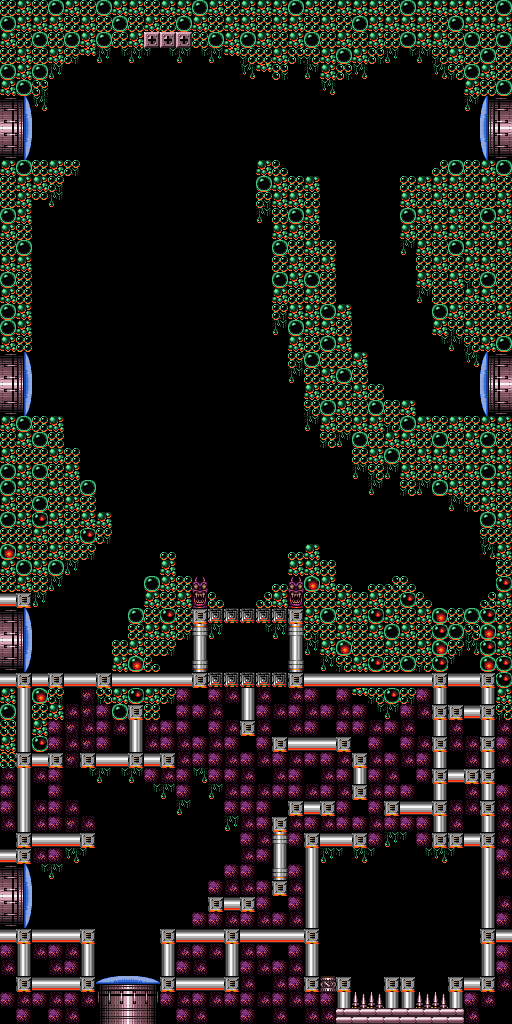

In [27]:
limage = graphics.image_from_state(default(objnames["room_header_0x7acb3"]), rom_m)
# Gross PIL stuff
limage2 = limage.convert("RGB")
limage2

In [28]:
level_array = objnames["room_header_0x7acb3"].state_chooser.default.level_data.level_array.layer1

In [29]:
from world_rando.room_perception.isovision import *

In [30]:
is_air = mk_is_air(level_array)

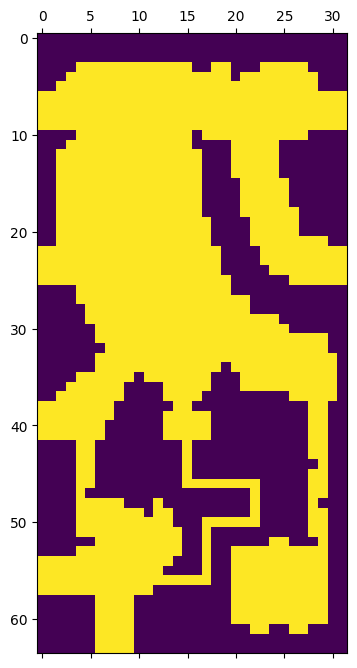

In [31]:
matshow(is_air.T)

In [35]:
from world_rando.room_perception.perceptual_flux import *

In [103]:
surfaces, subsegs = mk_lines(is_air)
#surfaces = mk_tiles(is_air)

In [104]:
len(surfaces)

202

In [105]:
from matplotlib import collections as mc

In [106]:
surfaces[0:1]

[(c(0,6), c(2,6))]

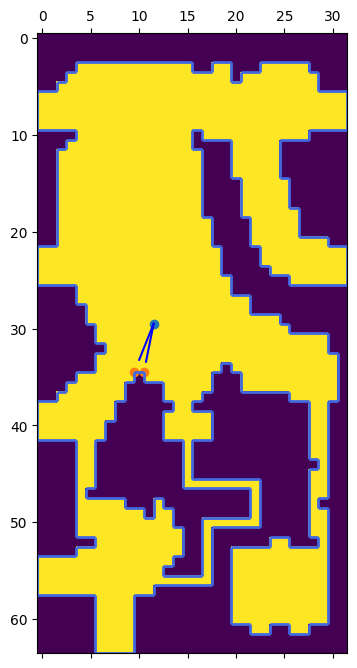

In [107]:
# Draw the surfaces
# MPL draws the matrix squares centered at the coordinate

#matshow(is_air[:10,:10].T)
matshow(is_air.T)
draw_segs(surfaces)
#scatter(range(5),range(5))
#scatter(30-.5, 12-.5)
scatter(12-.5, 30-.5)
#scatter(12, 30)
#scatter(13, 30)
scatter([10-.5, 11-.5], [35-.5, 35-.5])
t1 = 1.9513027039072615
t2 = 1.7681918866447774
plot([12-.5, 12-.5 + 4 * math.cos(t2)], [30-.5, 30-.5 + 4 * math.sin(t2)], color="blue")
plot([12-.5, 12-.5 + 4 * math.cos(t1)], [30-.5, 30-.5 + 4 * math.sin(t1)], color="blue")
#scatter(25, 55)

In [108]:
test_point = Coord(12, 30)
#test_point = Coord(25, 55)
perception, fully_occluded = mk_perception(test_point, surfaces)

In [109]:
len(fully_occluded)

146

In [110]:
perception_clean = {k:v for k,v in perception.items() if v.size > 0}

In [111]:
len(perception_clean), len(perception)

(56, 202)

In [112]:
xs, ys, ts = triangularize(test_point, perception_clean)

In [113]:
from matplotlib.tri import Triangulation

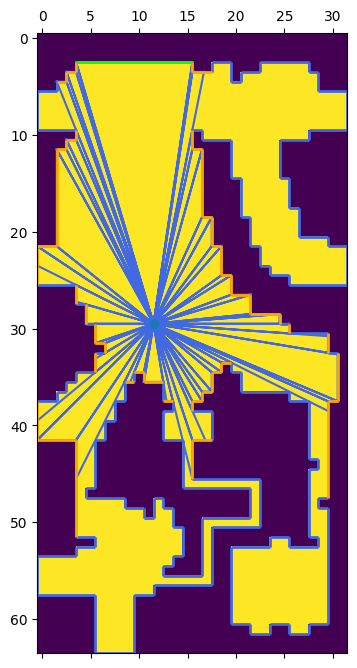

In [114]:
matshow(is_air.T)
xs_plot = xs - 0.5
ys_plot = ys - 0.5
triangles = Triangulation(xs_plot, ys_plot, ts)
triplot(triangles, color="royalblue")
#scatter(xs_plot, ys_plot)

drawc(test_point)

foxs = []
foys = []
for seg in fully_occluded:
    foxs.append(seg[0].x)
    foxs.append(seg[1].x)
    foys.append(seg[0].y)
    foys.append(seg[1].y)
fo_surfaces = [(a + offset, b + offset) for a,b in fully_occluded]
#scatter(np.array(foxs) -.5, np.array(foys) -.5)
draw_segs(fully_occluded)
draw_segs(perception_clean.keys(), "orange")

#seg_start = Coord(16, 4)
#seg_end = Coord(18, 4)
#seg = (seg_start, seg_end)
#seg_b = (Coord(16, 10), Coord(16, 12))
#seg_c = (Coord(16, 12), Coord(17, 12))
#draw_segs([seg, seg_b, seg_c], color="lime")

#seg2_start = Coord(16, 42)
#seg2_end = Coord(18, 42)
#seg2 = (seg2_start, seg2_end)
#draw_segs([seg2], color="lime")

# Fixed
#seg_start = Coord(31, 33)
#seg_end = Coord(31, 38)
#seg = (seg_start, seg_end)
#draw_segs([seg], color="lime")

seg3_start = Coord(4, 3)
seg3_end = Coord(16, 3)
#seg3_b = (Coord(26, 30), Coord(26, 31))
#seg3_c = (Coord(25, 29), Coord(25, 30))
seg3 = (seg3_start, seg3_end)
#draw_segs([seg3, seg3_b, seg3_c], color="lime")
draw_segs([seg3], color="lime")


In [115]:
test2 = Coord(12, 31)
perception2, _ = mk_perception(test2, surfaces)
perception3 = mk_perception_good(test2, perception2, subsegs)

In [116]:
perception2[seg3]

Interval(4.434089321379578, 4.854286034988854)

In [117]:
subsegs[seg3]

[(c(4,3), c(5,3)),
 (c(5,3), c(6,3)),
 (c(6,3), c(7,3)),
 (c(7,3), c(8,3)),
 (c(8,3), c(9,3)),
 (c(9,3), c(10,3)),
 (c(10,3), c(11,3)),
 (c(11,3), c(12,3)),
 (c(12,3), c(13,3)),
 (c(13,3), c(14,3)),
 (c(14,3), c(15,3)),
 (c(15,3), c(16,3))]

In [118]:
[perception3[s] for s in subsegs[seg3]]

[Interval(4.434089321379578, 4.4674103172578254),
 Interval(4.4674103172578254, 4.501295647161943),
 Interval(4.501295647161943, 4.535680124314653),
 Interval(4.535680124314653, 4.570491925780526),
 Interval(4.570491925780526, 4.605653307735555),
 Interval(4.605653307735555, 4.641081515599399),
 Interval(4.641081515599399, 4.676689867705366),
 Interval(4.676689867705366, 4.71238898038469),
 Interval(4.71238898038469, 4.7480880930640135),
 Interval(4.7480880930640135, 4.78369644516998),
 Interval(4.78369644516998, 4.819124653033826),
 Interval(4.819124653033826, 4.854286034988854)]

In [119]:
sum(list(mk_surface_probs(perception3).values()))

1.0

In [120]:
sum(list(mk_surface_probs(perception2).values()))

1.0

In [121]:
perception_surface_distance(perception, perception2)

0.011172773129360714

In [123]:
surface_probs = mk_all_surface_probs(is_air, surfaces, subsegs, good=True)

  0%|          | 0/2048 [00:00<?, ?it/s]

In [127]:
infos = mk_neighbor_infos(is_air, surface_probs)

In [128]:
tile_dists = mk_distance(is_air)

In [159]:
surfaces2 = mk_tiles(is_air)

In [160]:
surface_probs2 = mk_all_surface_probs(is_air, surfaces2, {}, good=False)

  0%|          | 0/2048 [00:00<?, ?it/s]

In [161]:
infos2 = mk_neighbor_infos(is_air, surface_probs2)

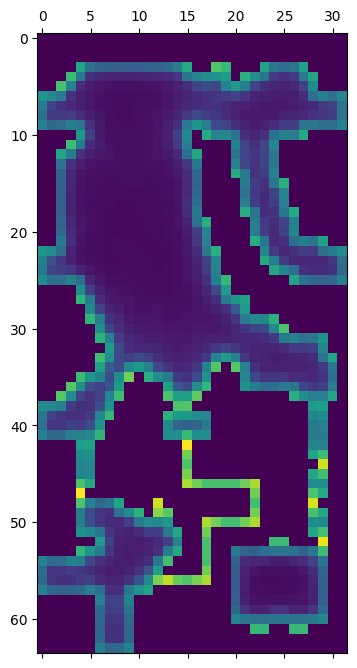

In [165]:
matshow(infos.T)

In [130]:
#TODO: scale based on distance
#TODO: integral estimation
#TODO: smoothed surfaces
#TODO: another pdf distance metric?
#TODO: more that two points in the divergence?
#TODO: penalty for merging larger regions?
#TODO: Local minima
# 
#TODO: Merging regions based on the divergence of their mixtures
#TODO: weighted sum based on the distance to the edge
#TODO: separate wall cap segments
#TODO: treat quicksand as air
#TODO: make slope tiles have sloped segments
#TODO: max size for surfaces

In [131]:
minima = mk_minima(infos, is_air)

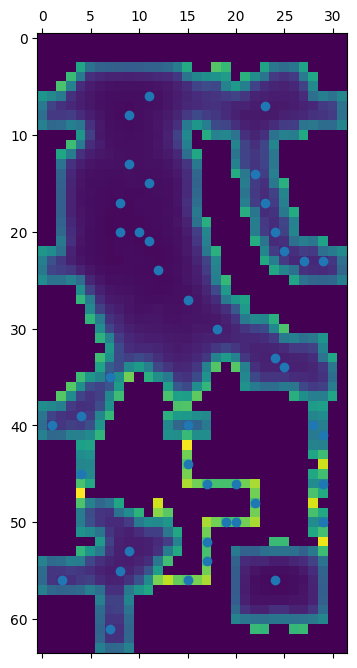

In [132]:
matshow(infos.T)
scatter([c.x for c in minima], [c.y + 0. for c in minima])

In [133]:
glom = agglomerate(minima, surface_probs, 0.6)

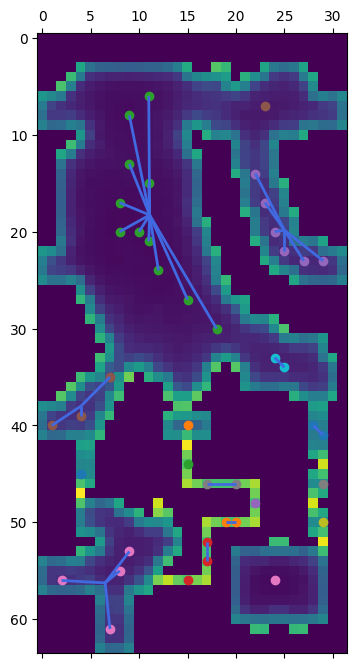

In [134]:
matshow(infos.T)
draw_cluster(glom)

In [432]:
bad_surfaces = mk_lines(is_air)

In [433]:
points = set([])
for (c1, c2) in bad_surfaces:
    points.add(c1)
    points.add(c2)

In [434]:
def tri_coord(tri, index):
    return Coord(tri.x[index], tri.y[index])

def tri_voronoi(tri):
    centers = []
    for t in tri.triangles:
        c1, c2, c3 = [tri_coord(tri, k) for k in t]
        center = (c1 + c2 + c3).scale(1/3)
        centers.append(center)
    return centers

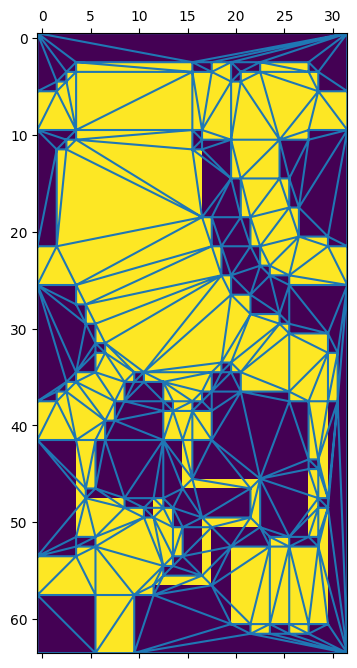

In [435]:
xs = np.array([c.x for c in points])
ys = np.array([c.y for c in points])
xs_plot = xs - 0.5
ys_plot = ys - 0.5
tri = Triangulation(xs_plot, ys_plot)
centers = tri_voronoi(tri)
cxs = [c.x for c in centers]
cys = [c.y for c in centers]
matshow(is_air.T)
triplot(tri)
#scatter(cxs, cys)

In [169]:
ghz_is_air, ghz_sps, ghz_infos = compute_surfaces("room_header_0x79e52", objnames)

  0%|          | 0/8192 [00:00<?, ?it/s]

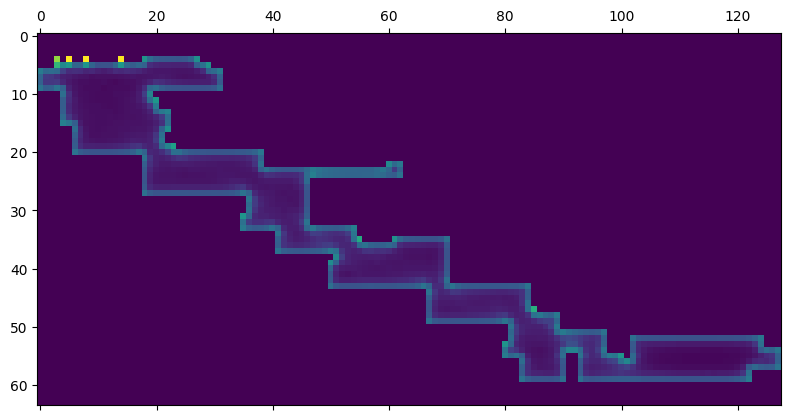

In [170]:
matshow(ghz_infos.T)

In [171]:
ghz_minima = mk_minima(ghz_infos, ghz_is_air)

In [172]:
glom = agglomerate(ghz_minima, ghz_sps, 0.6)

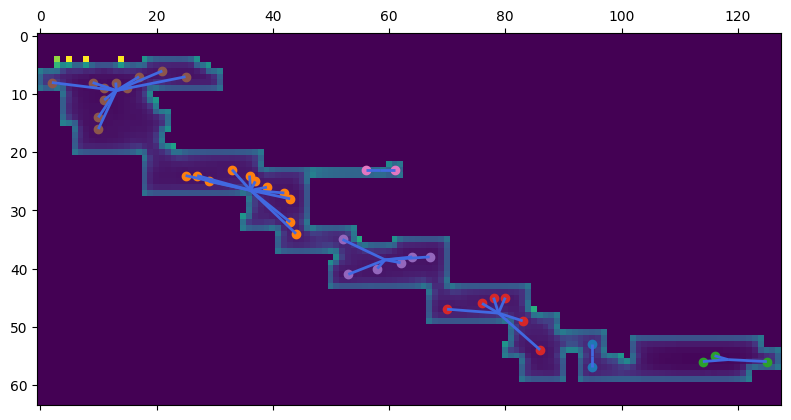

In [173]:
matshow(ghz_infos.T)
draw_cluster(glom)

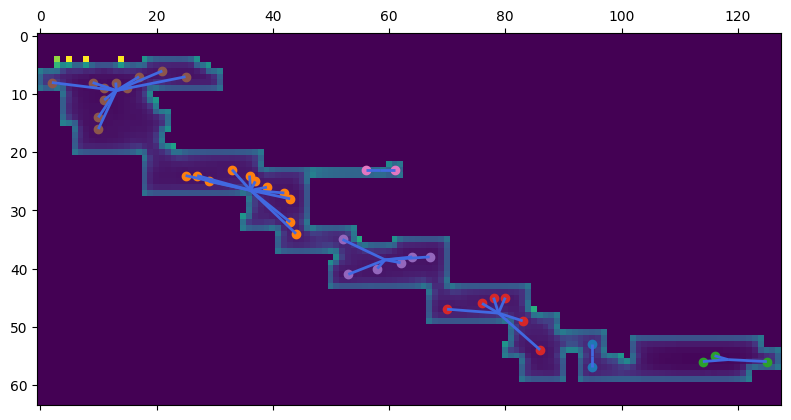

In [175]:
_ = show_clusters(ghz_is_air, ghz_sps, ghz_infos)

  0%|          | 0/12800 [00:00<?, ?it/s]

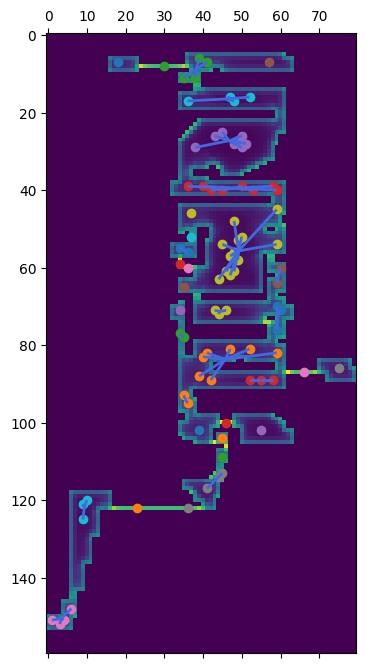

In [177]:
# Big Pink - 0x79d19
# Cathedral - 0x7a788
# Cathedral Entrance - 0x7a7b3
surface_stuff = compute_surfaces("room_header_0x79d19", objnames)
glom = show_clusters(*surface_stuff)

In [182]:
from tqdm.notebook import tqdm

In [183]:
def mk_partition(is_air, surface_probs, glom):
    part = zeros_like(is_air)
    indices = {}
    for i,k in enumerate(glom):
        indices[k] = i+1 # 0 will be solid
    for c in tqdm(iter2d(is_air), total = is_air.shape[0] * is_air.shape[1]):
        if is_air[c] == 1:
            cluster = 0
            min_jsd = None
            for k, m in glom.items():
                jsd = surface_prob_jsd(surface_probs[c], m)
                if min_jsd is None or jsd < min_jsd:
                    min_jsd = jsd
                    cluster = indices[k]
            part[c] = cluster
    return part

In [184]:
bp_is_air, bp_sps, bp_infos = surface_stuff
bp_partition = mk_partition(bp_is_air, bp_sps, glom)

  0%|          | 0/12800 [00:00<?, ?it/s]

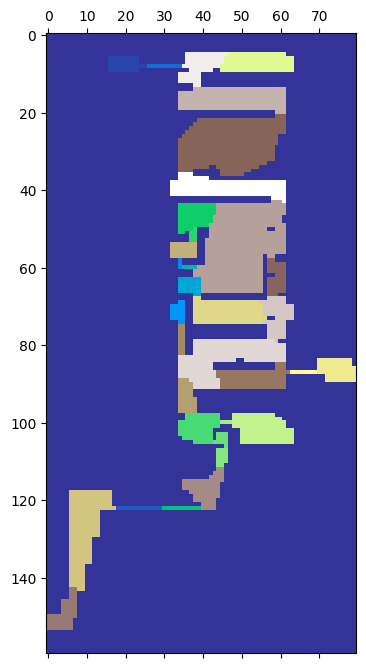

In [189]:
matshow(bp_partition.T, cmap="terrain")

In [264]:
def tbt(is_air, c, v=1):
    for x in range(4):
        for y in range(4):
            cc = c + Coord(x,y)
            is_air[cc] = v

In [282]:
line_is_air = np.zeros((60, 60))
for c in iter2d(line_is_air):
    line_is_air[c] = -1
for x in range(5, 50, 6):
    for y in range(5, 5 + x):
        line_is_air[x,y] = 1
        line_is_air[x+1, y] = 1
for x in range(4, 49, 6):
    tbt(line_is_air, Coord(x, 5))
    yy = 5 + x
    tbt(line_is_air, Coord(x, yy))

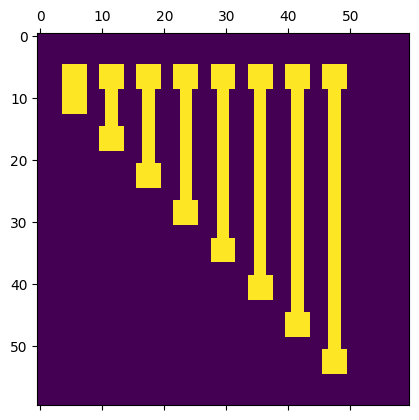

In [283]:
matshow(line_is_air.T)

In [284]:
#TODO: cut up compute_surfaces into more parts
surfaces, subsegs = mk_lines(line_is_air)
surface_probs = mk_all_surface_probs(line_is_air, surfaces, subsegs)
infos = mk_neighbor_infos(line_is_air, surface_probs)

  0%|          | 0/3600 [00:00<?, ?it/s]

In [285]:
minima = mk_minima(infos, line_is_air)
glom = agglomerate(minima, surface_probs, 0.6)

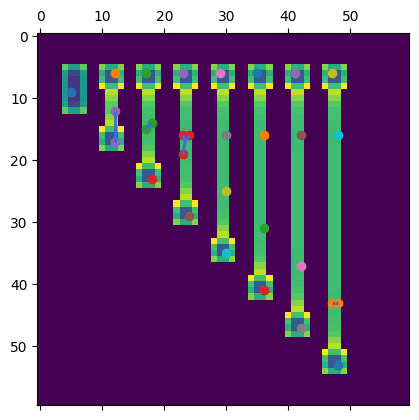

In [286]:
matshow(infos.T)
draw_cluster(glom)

In [276]:
collonade = np.zeros((40, 20))
for c in iter2d(collonade):
    collonade[c] = 1
for x in range(1, 36, 6):
    tbt(collonade, Coord(x, 5), -1)

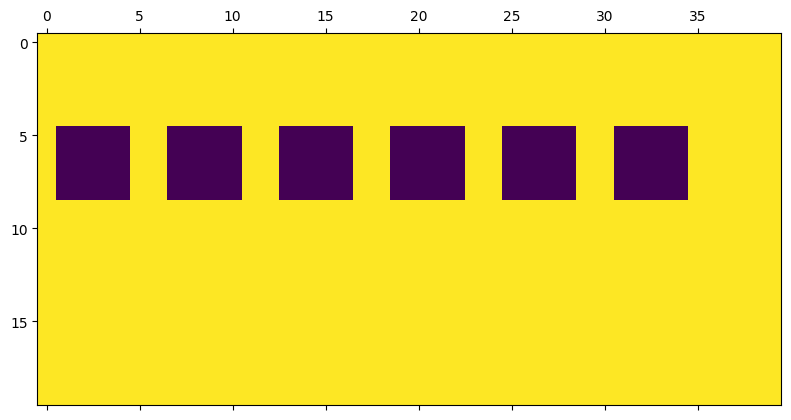

In [277]:
matshow(collonade.T)

In [278]:
#TODO: cut up compute_surfaces into more parts
surfaces, subsegs = mk_lines(collonade)
surface_probs = mk_all_surface_probs(collonade, surfaces, subsegs)
infos = mk_neighbor_infos(collonade, surface_probs)

  0%|          | 0/800 [00:00<?, ?it/s]

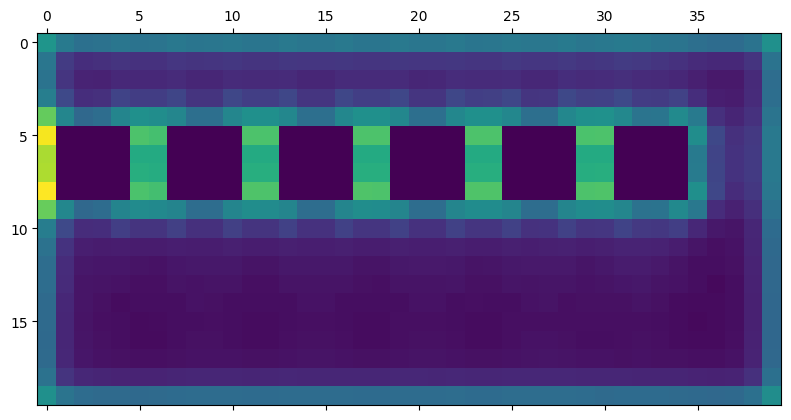

In [279]:
matshow(infos.T)

In [280]:
minima = mk_minima(infos, collonade)
glom = agglomerate(minima, surface_probs, 0.6)

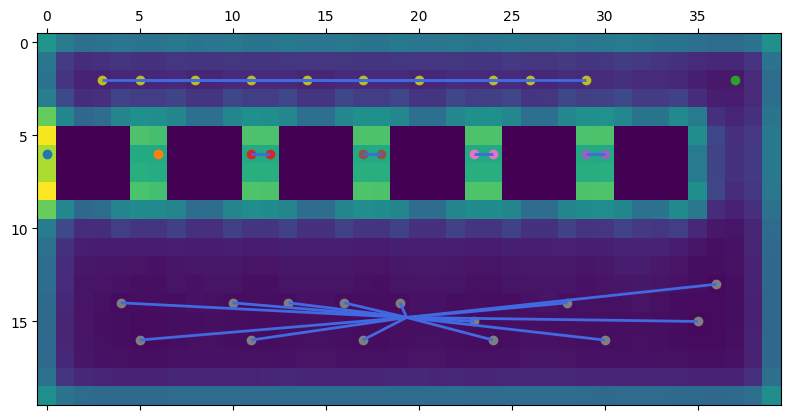

In [281]:
matshow(infos.T)
draw_cluster(glom)

In [357]:
scale_test = np.zeros((60, 200))
for c in iter2d(scale_test):
    scale_test[c] = -1
# 3x3
top = 1
bottom = 12
#bottom = 4
for x in range(1,4):
    for y in range(1,4):
        scale_test[x,y] = 1
        scale_test[x,y+bottom] = 1
for y in range(3, bottom + 1):
    scale_test[2, y] = 1
    
# 9x9
offset = Coord(10, 0)

for x in range(1, 10):
    for y in range(1, 10):
        cx = Coord(x, y)
        scale_test[cx + offset] = 1
        scale_test[cx + offset + Coord(0, bottom * 3)] = 1
for y in range(3, bottom*3 + 1):
    scale_test[offset.x + 4 : offset.x  + 7, y] = 1

offset2 = Coord(25, 0)
for x in range(1, 28):
    for y in range(1, 28):
        cx = Coord(x,y)
        scale_test[cx + offset2] = 1
        scale_test[cx + offset2 + Coord(0, bottom*9)] = 1
for y in range(3, bottom*9 + 1):
    scale_test[offset2.x + 10: offset2.x + 19, y] = 1

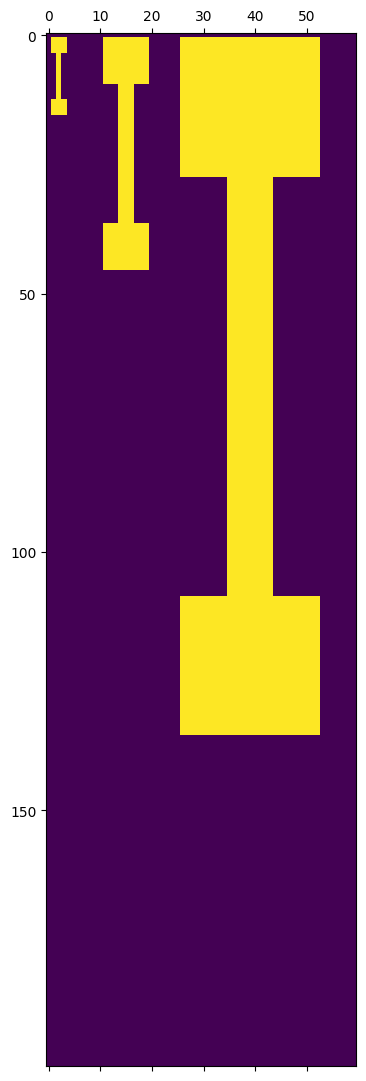

In [358]:
matshow(scale_test.T)

In [359]:
#TODO: cut up compute_surfaces into more parts
surfaces, subsegs = mk_lines(scale_test)
surface_probs = mk_all_surface_probs(scale_test, surfaces, subsegs)
infos = mk_neighbor_infos(scale_test, surface_probs)

  0%|          | 0/12000 [00:00<?, ?it/s]

In [360]:
minima = mk_minima(infos, scale_test)
glom = agglomerate(minima, surface_probs, 0.6)

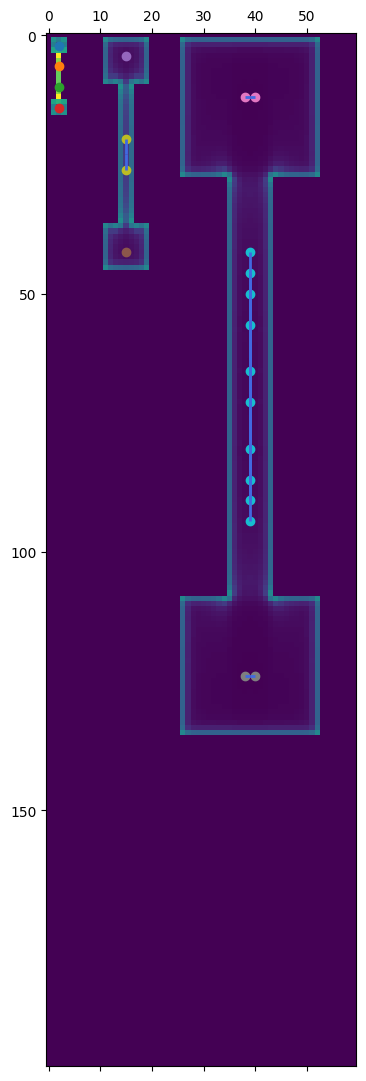

In [361]:
matshow(infos.T)
draw_cluster(glom)